# Exploratory Data Analysis

## Imports

In [24]:
# Automatic module reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Add project root
PROJ_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJ_ROOT))

# Notebooks imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Files

In [25]:
from src.dataset.plots import load_data

df_aerobic = load_data(PROJ_ROOT / "data/processed/aerobic_tidy.parquet")
df_anaerobic = load_data(PROJ_ROOT / "data/processed/anaerobic_tidy.parquet")

df_aerobic_curves = pd.read_csv(PROJ_ROOT / 'data/processed/aerobic_tidy_curves.csv')
df_anaerobic_curves = pd.read_csv(PROJ_ROOT / 'data/processed/anaerobic_tidy_curves.csv')
df_aero_anaero_curves = pd.read_csv(PROJ_ROOT / "data/processed/aero_anaero_tidy_curves.csv")


## 1. Curves

### 1.1 Unsmooth

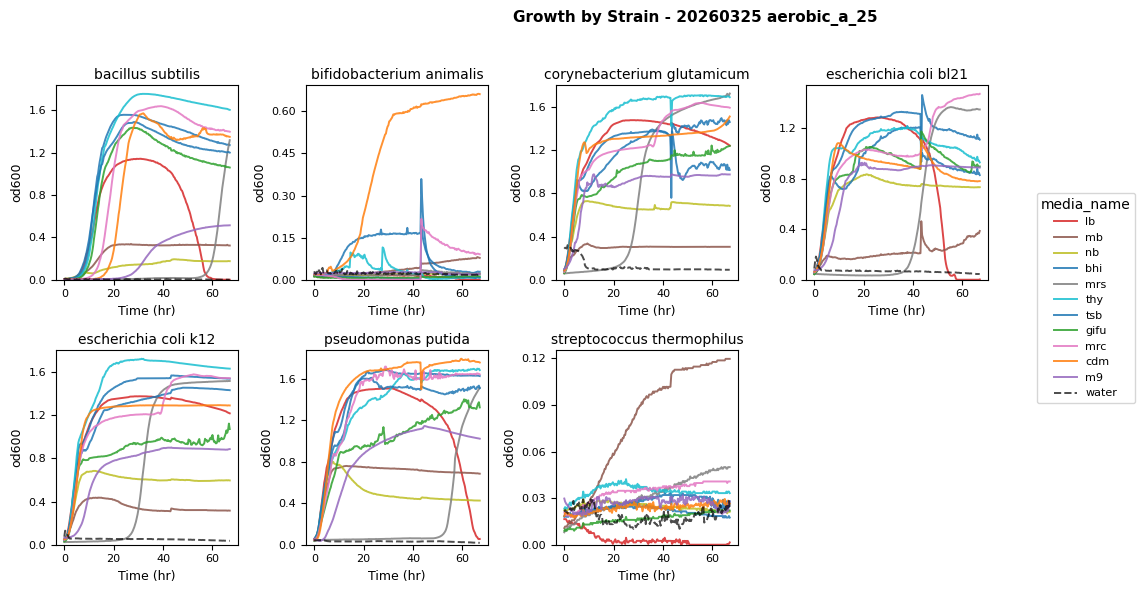

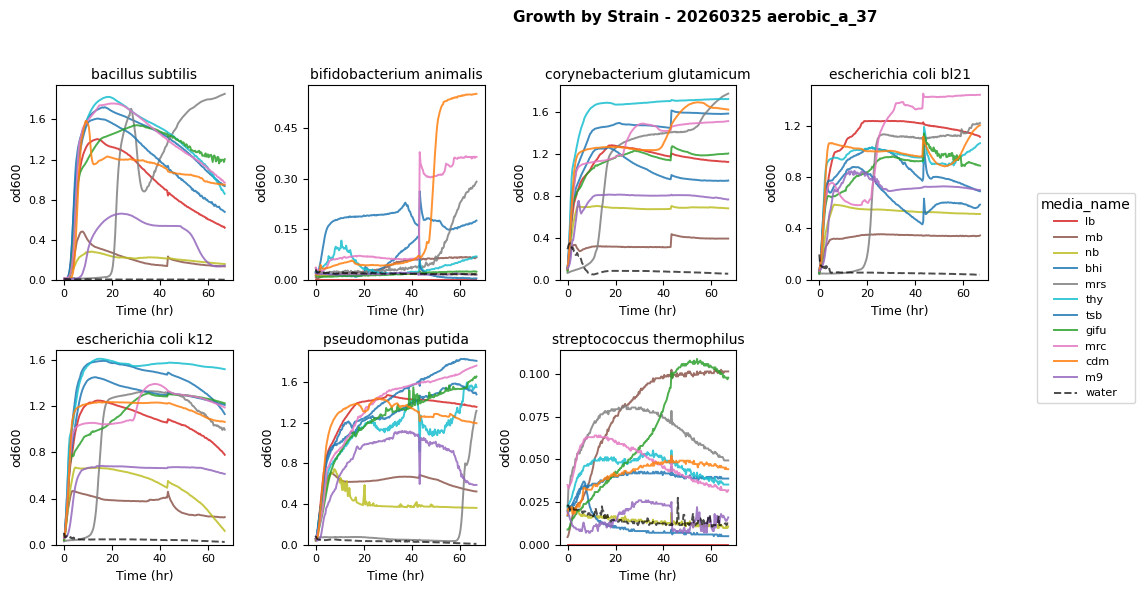

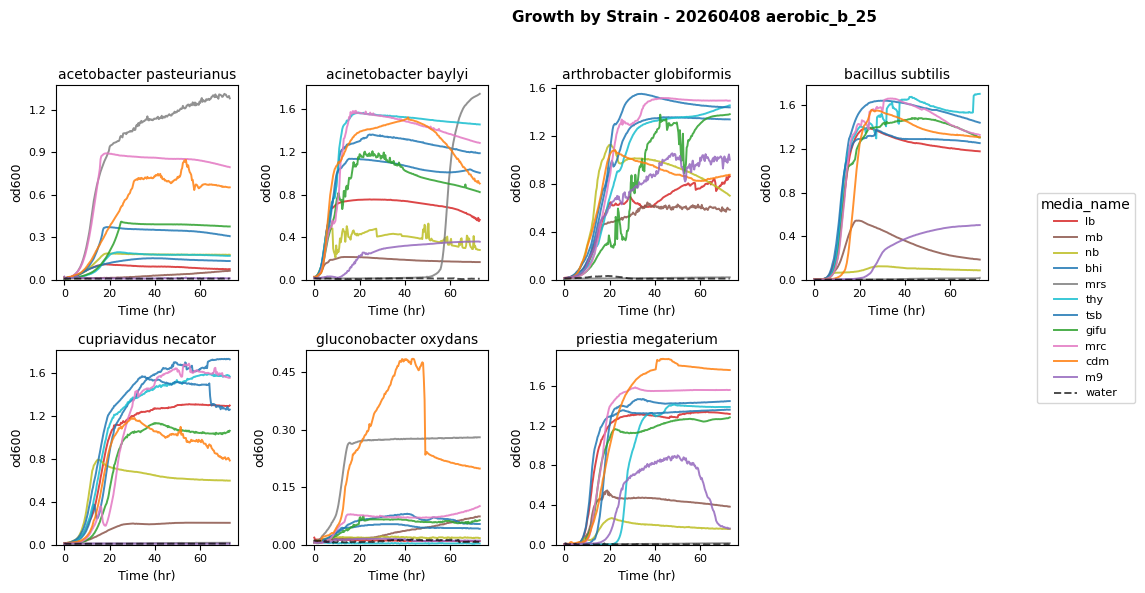

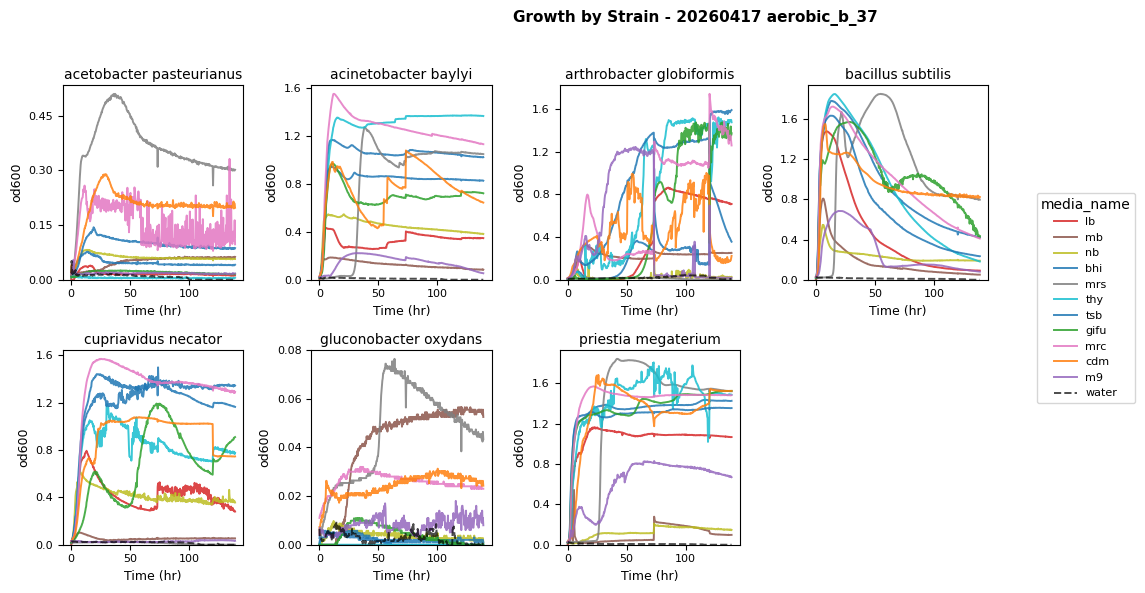

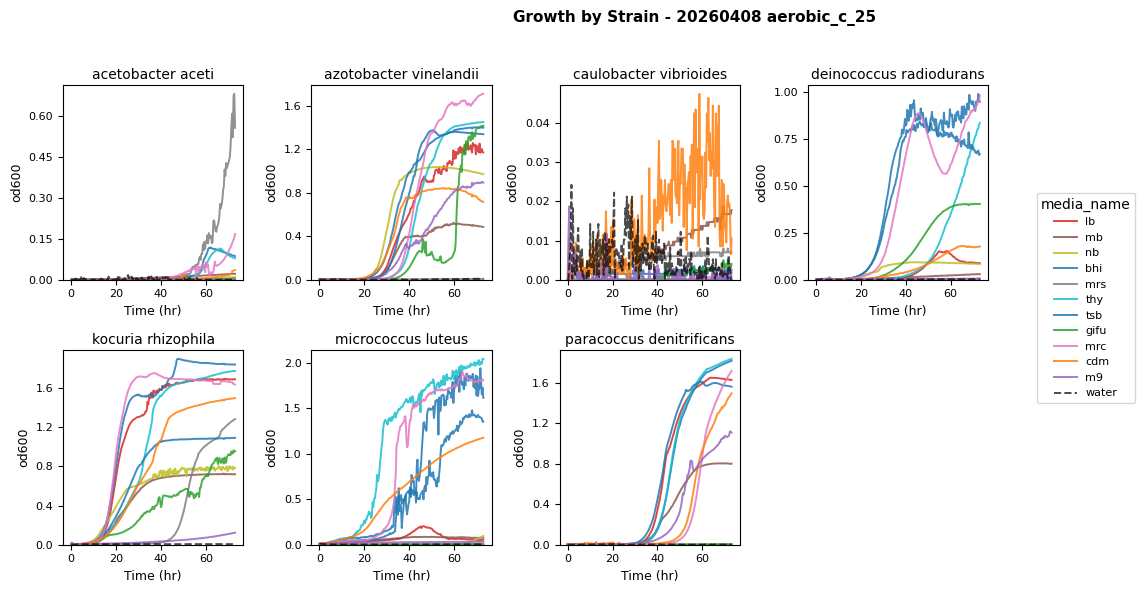

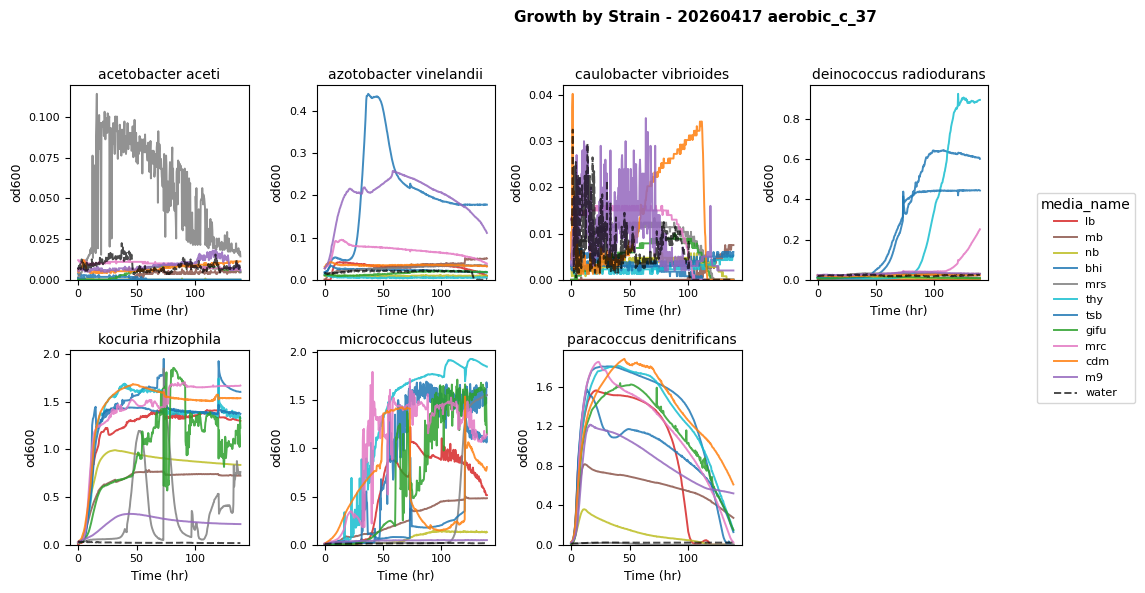

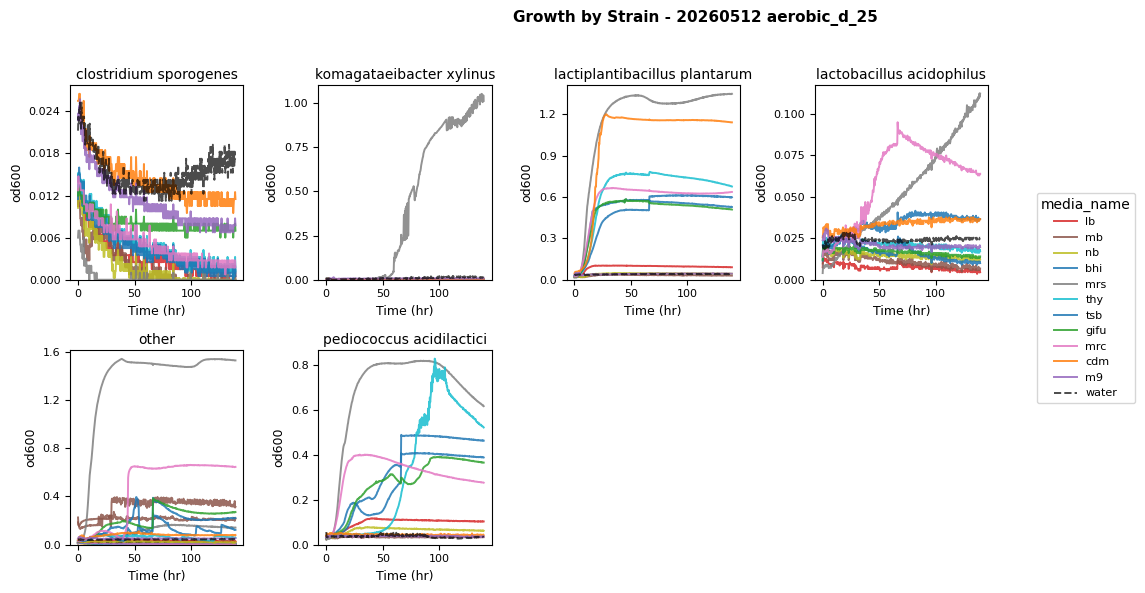

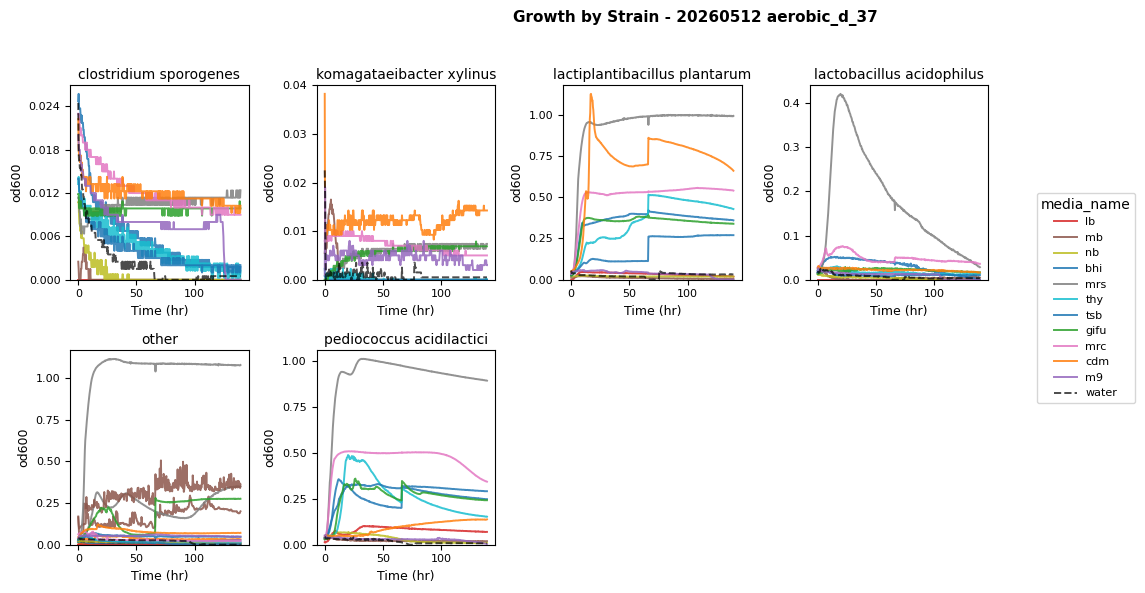

In [26]:
from src.dataset.plots import plot_growth_curves_by_strain

figs = plot_growth_curves_by_strain(df_aerobic, time_unit="hr")

### 1.2. Smooth

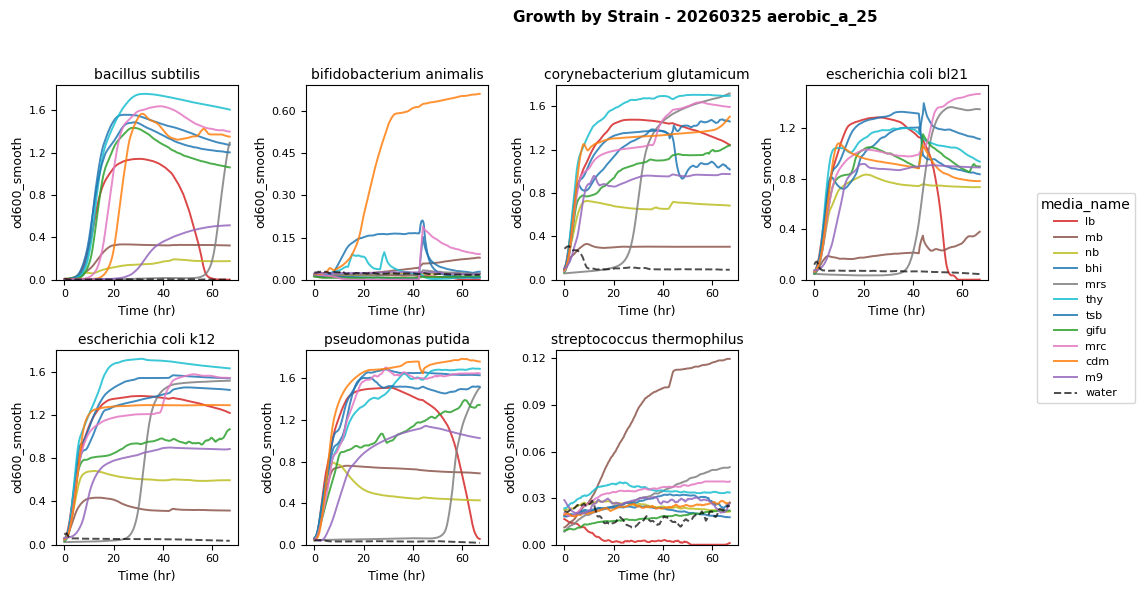

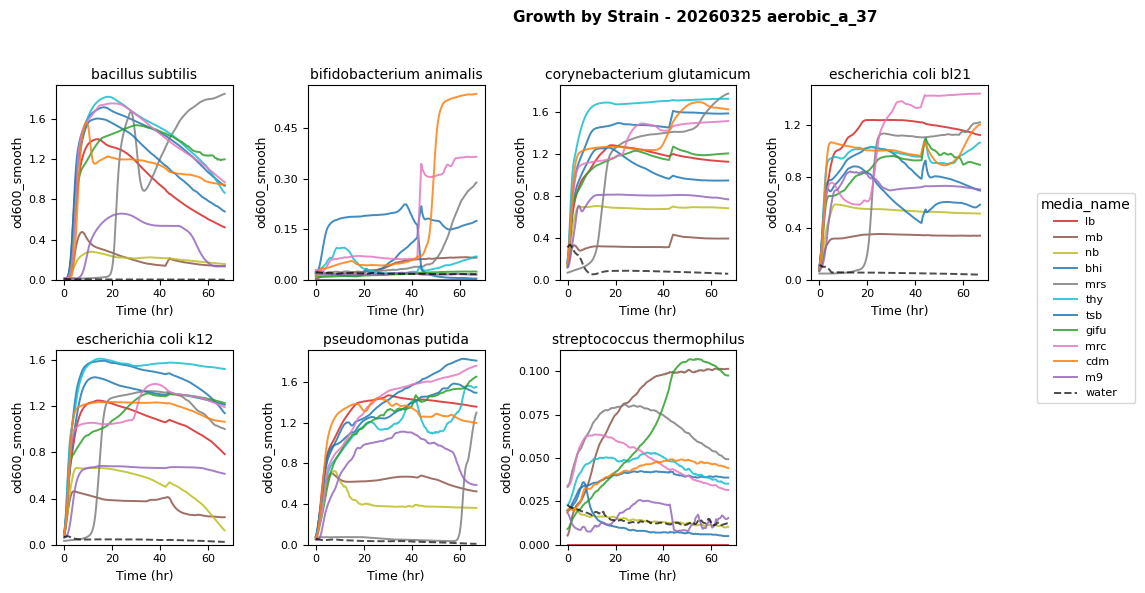

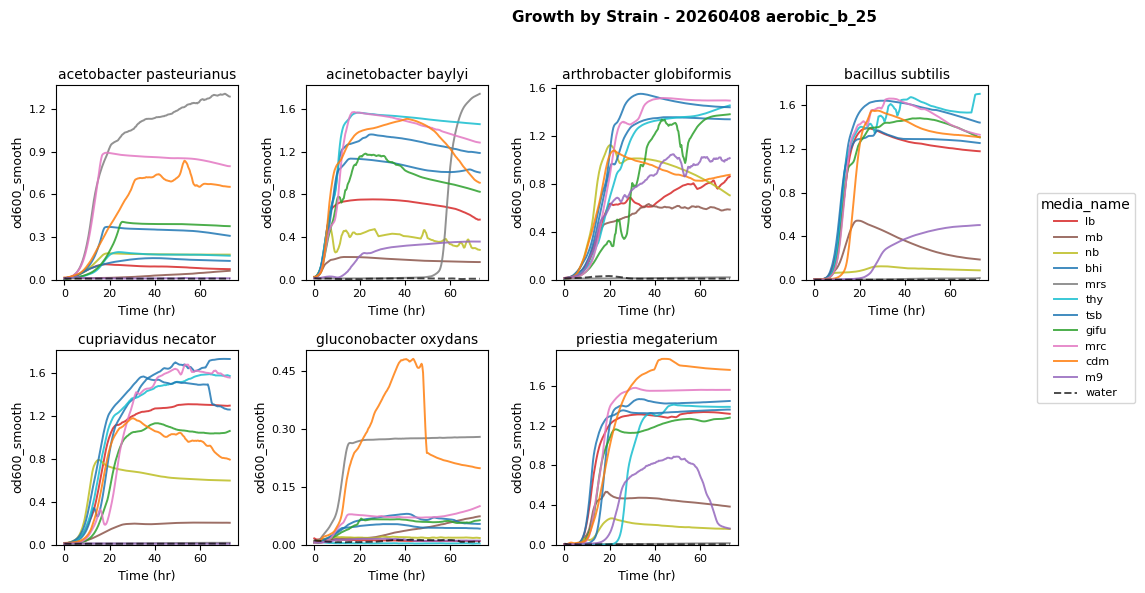

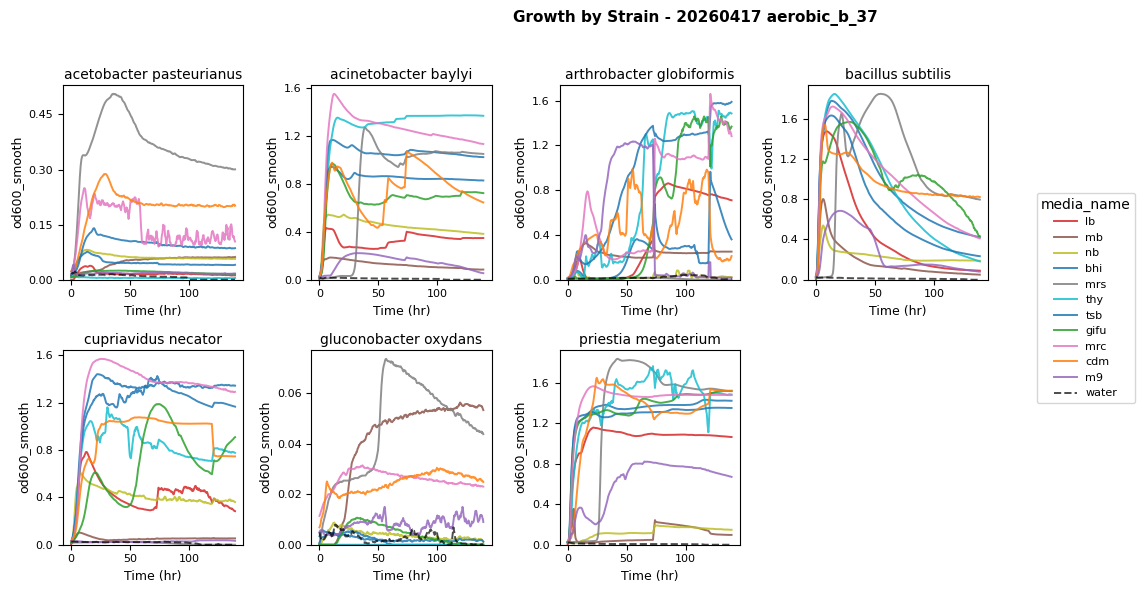

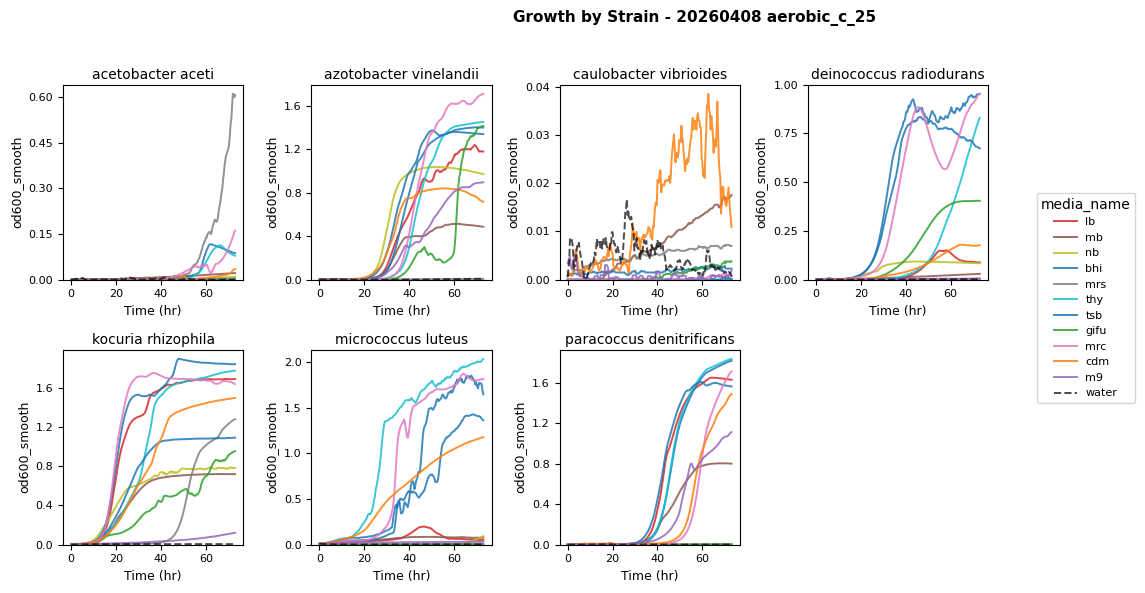

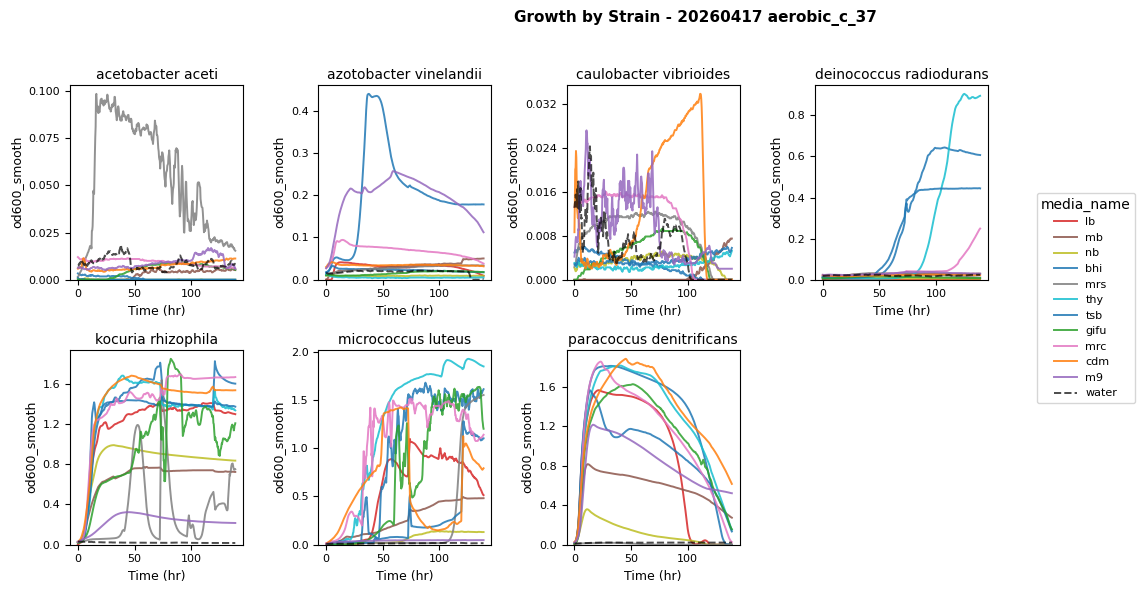

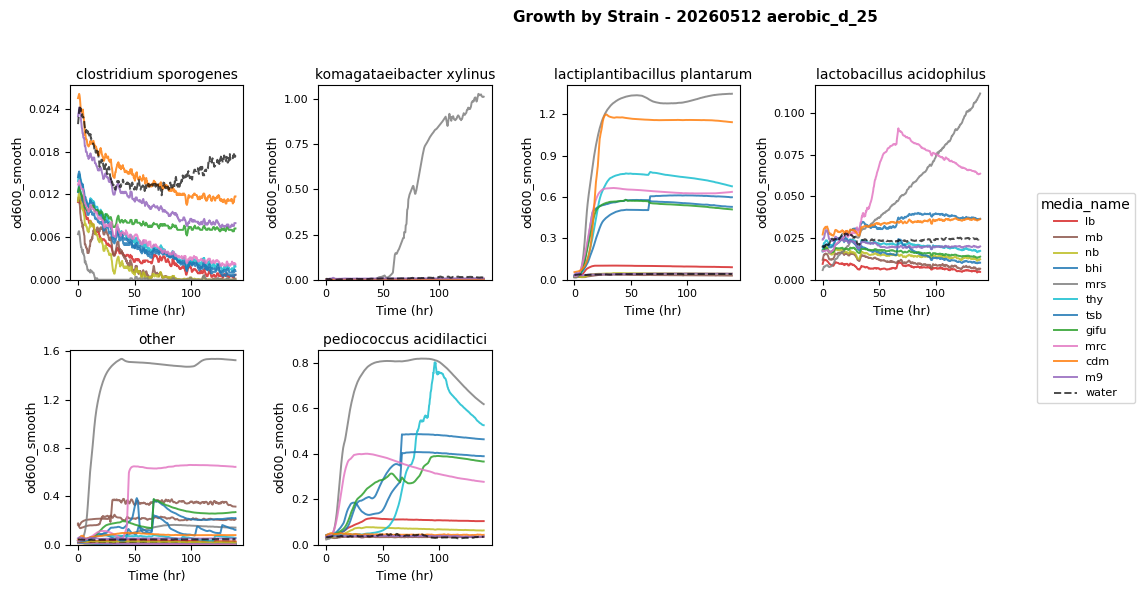

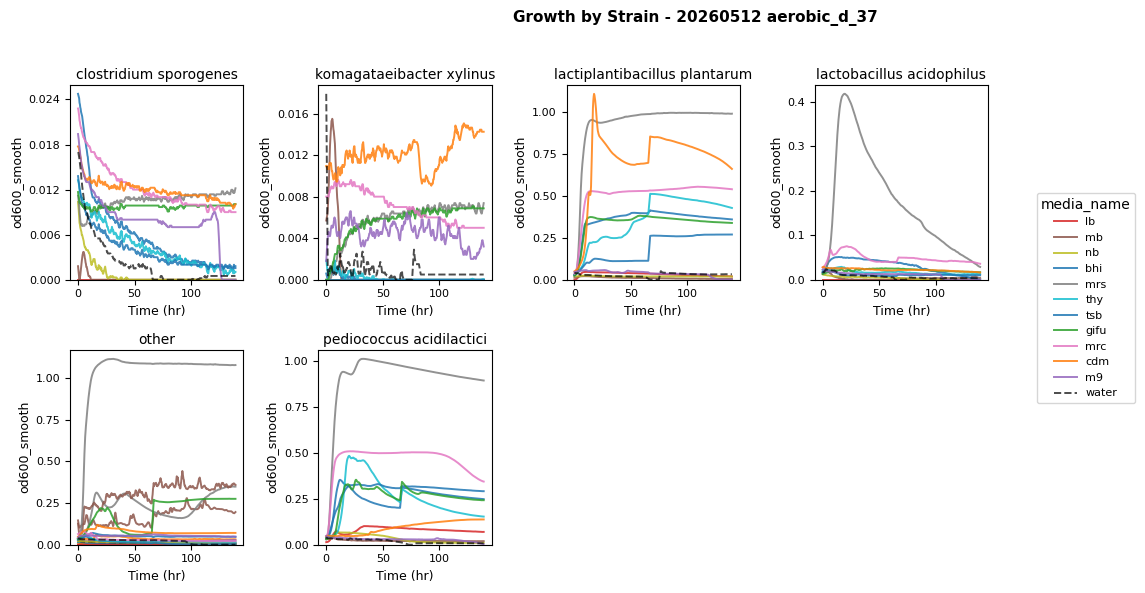

In [27]:
figs = plot_growth_curves_by_strain(df_aerobic, time_unit="hr", od_col="od600_smooth")

### 1.3 Unsmooth anaerobic

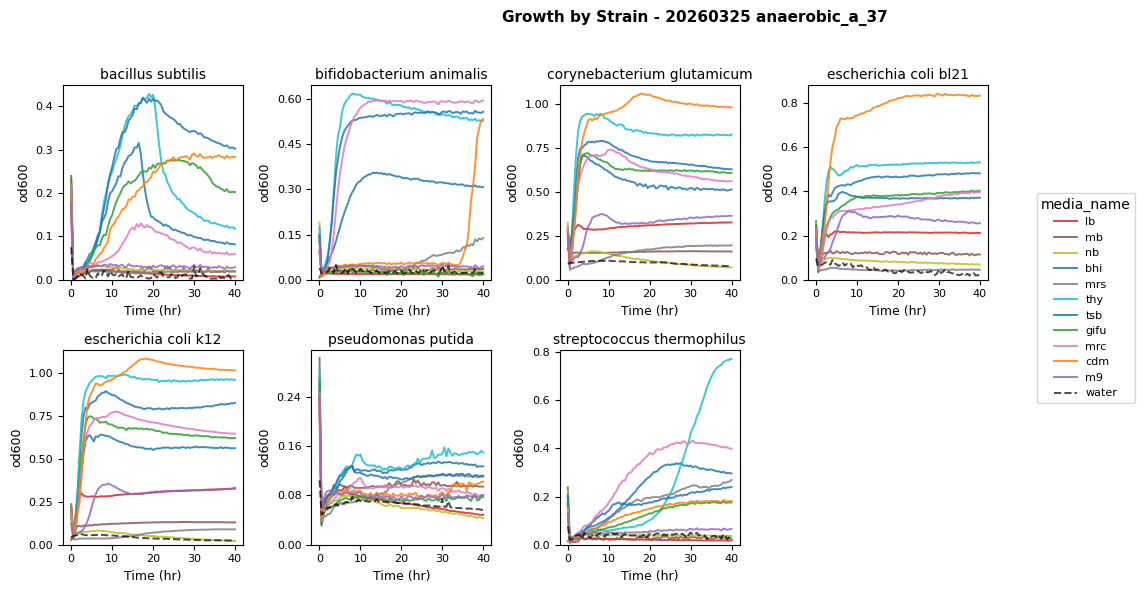

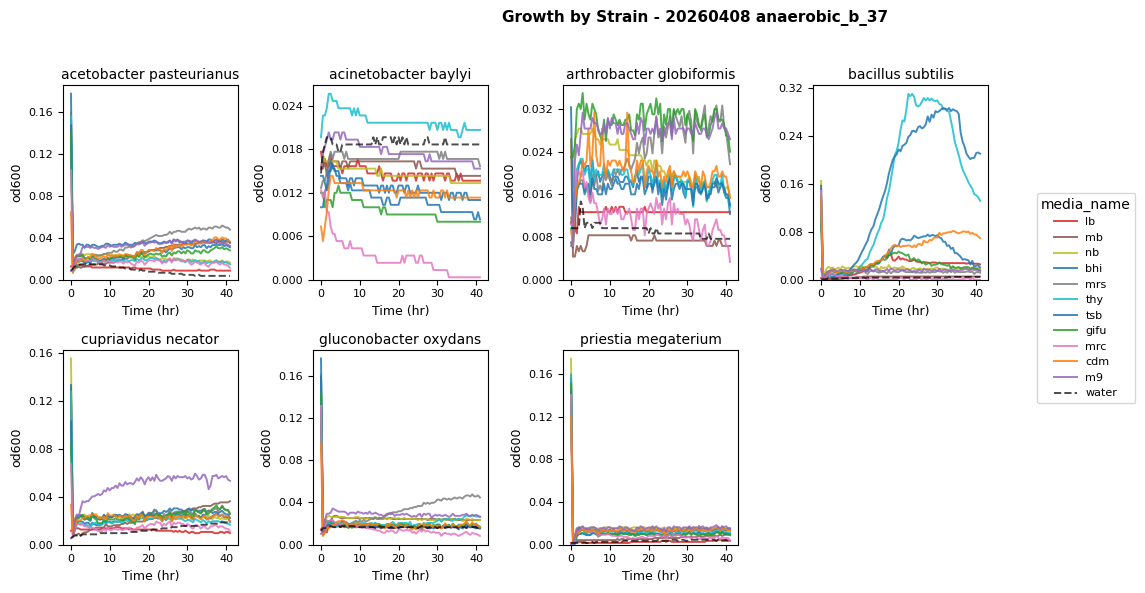

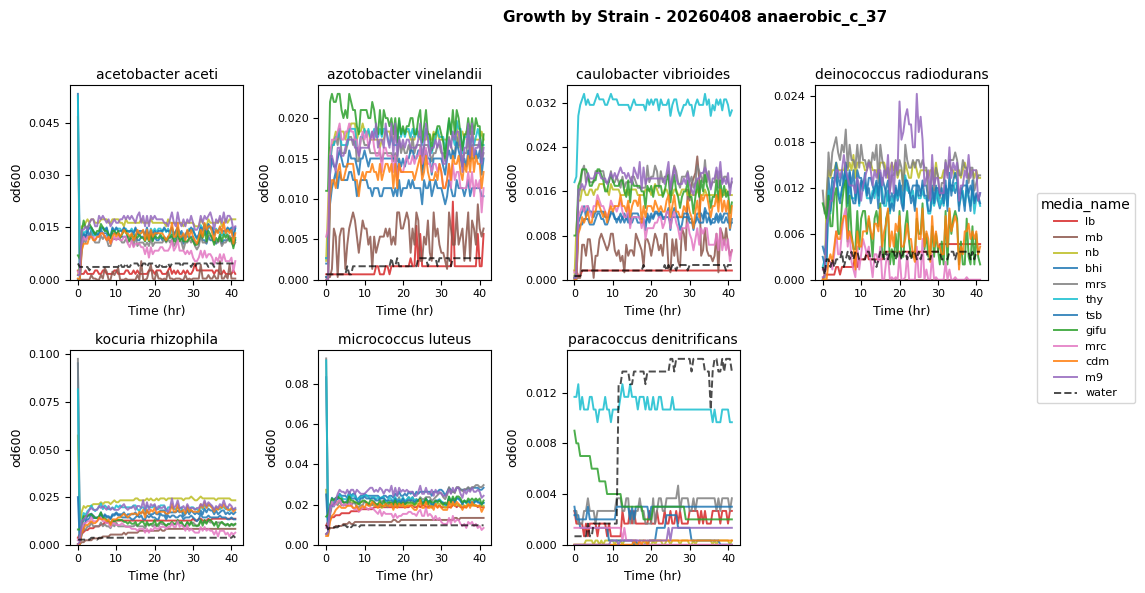

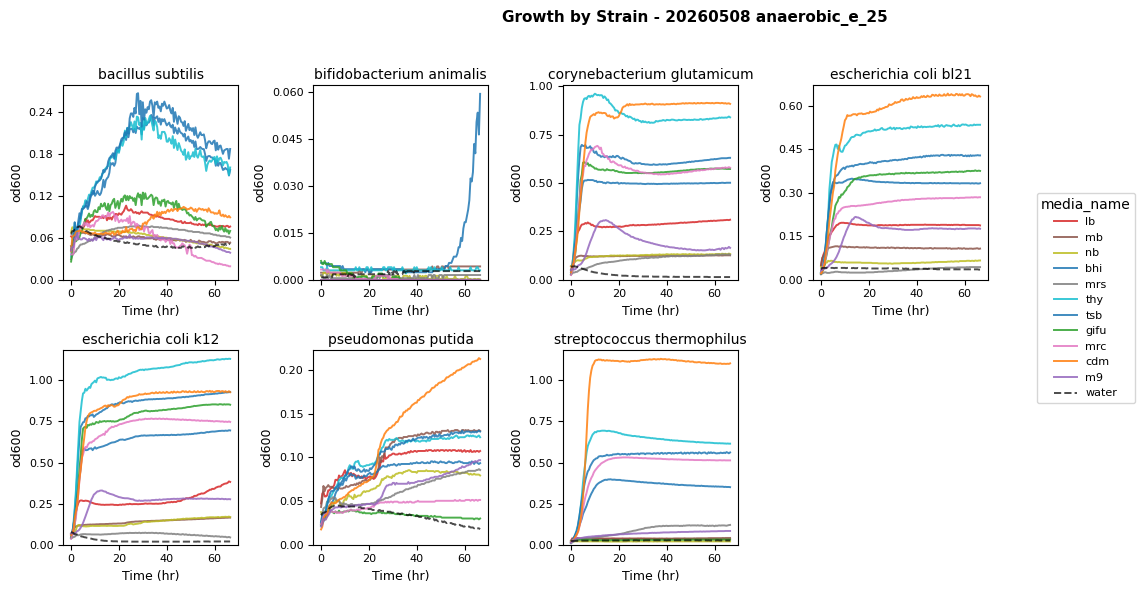

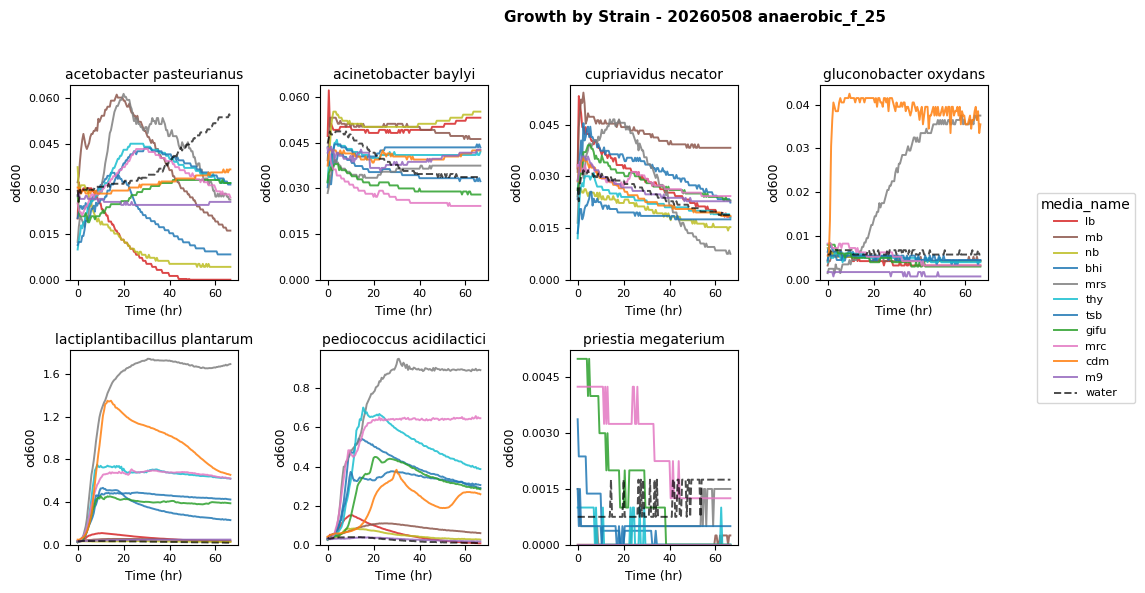

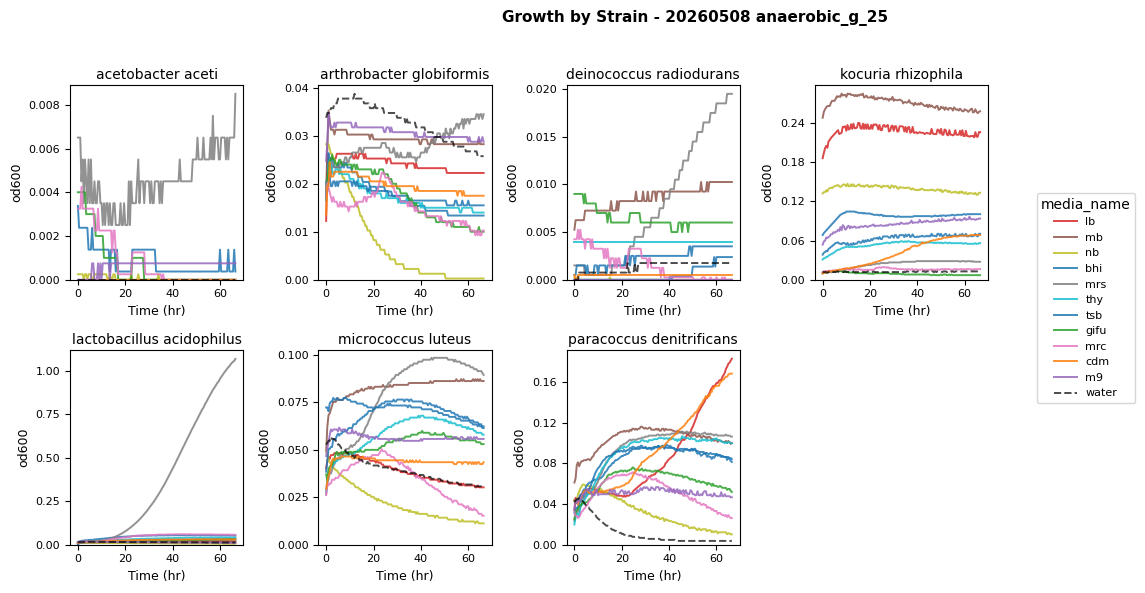

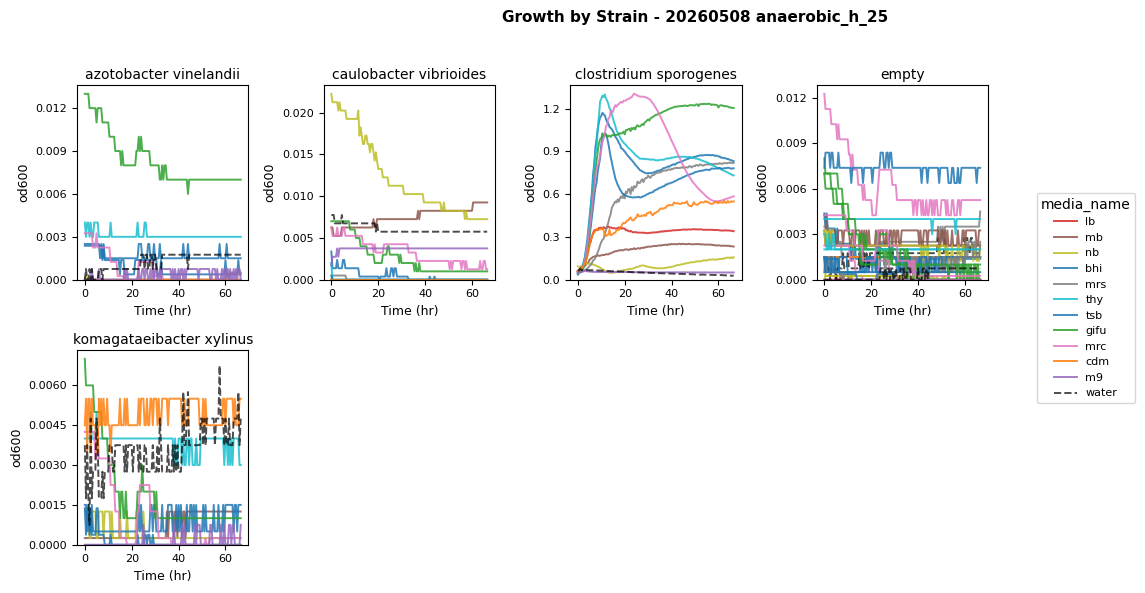

In [28]:
figs = plot_growth_curves_by_strain(df_anaerobic, time_unit="hr")

### 1.4. Smooth anaerobic

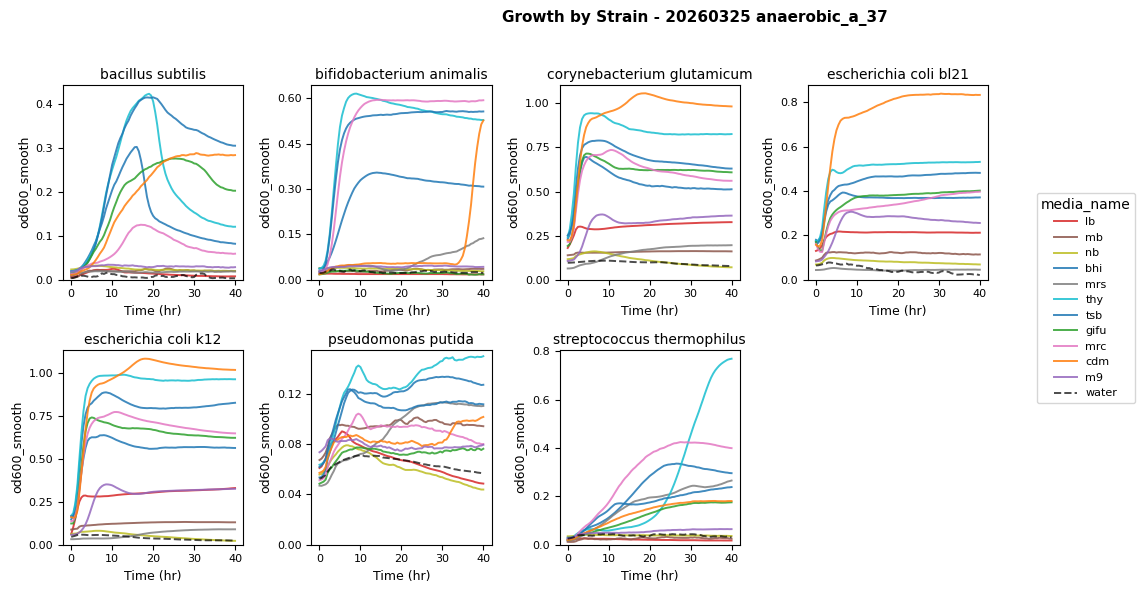

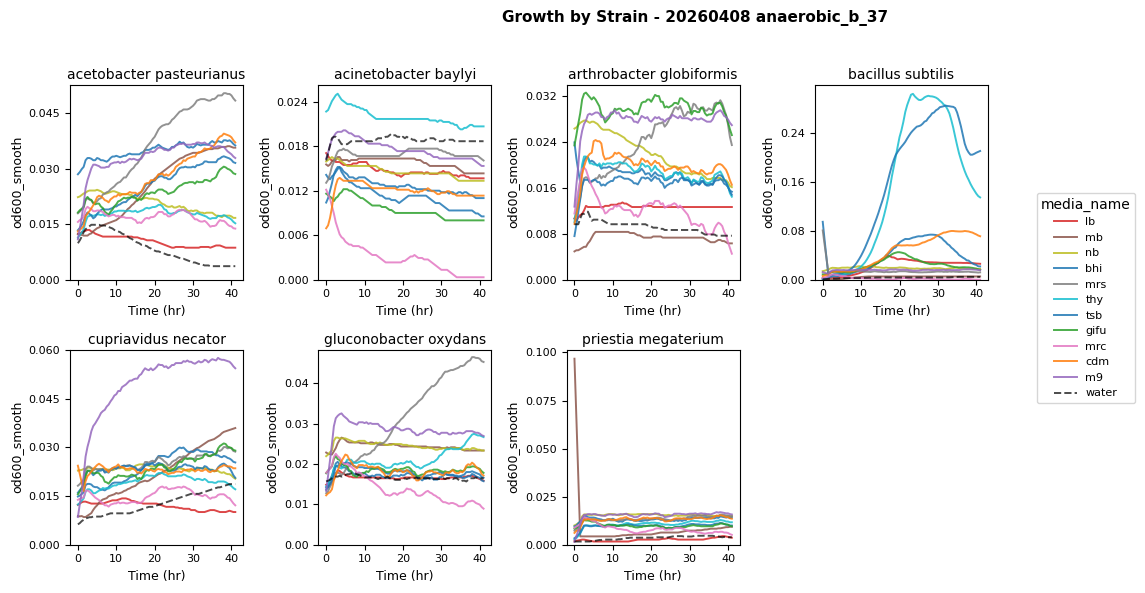

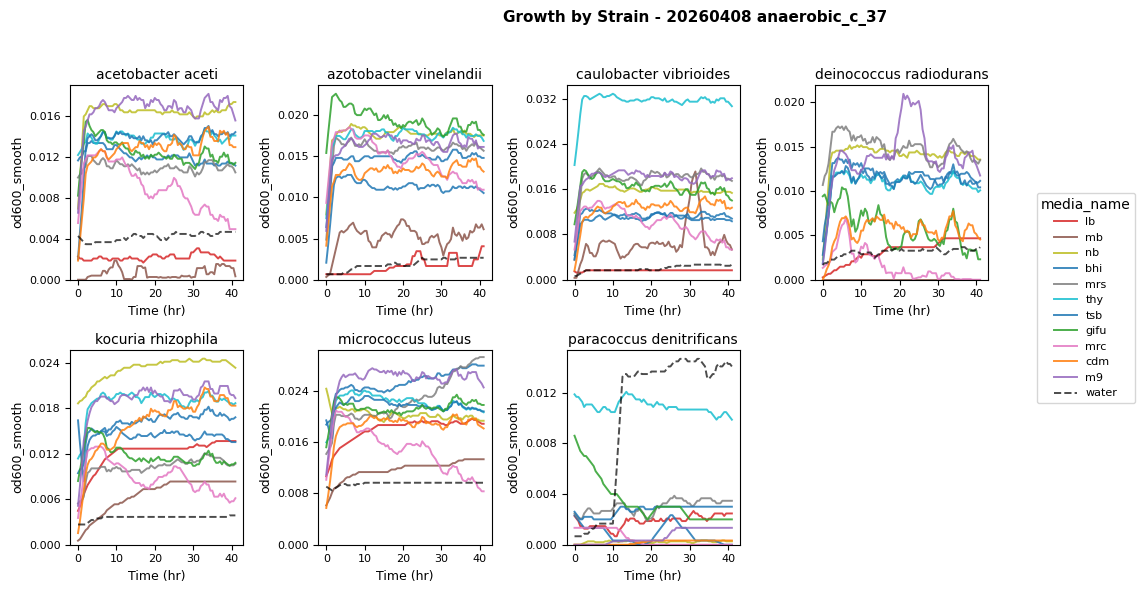

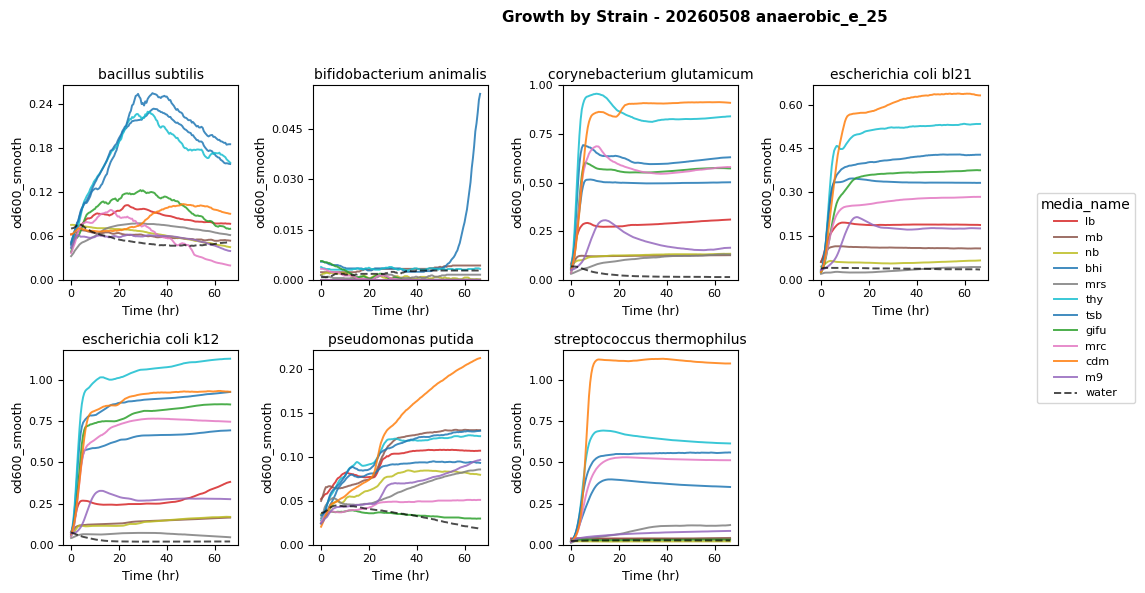

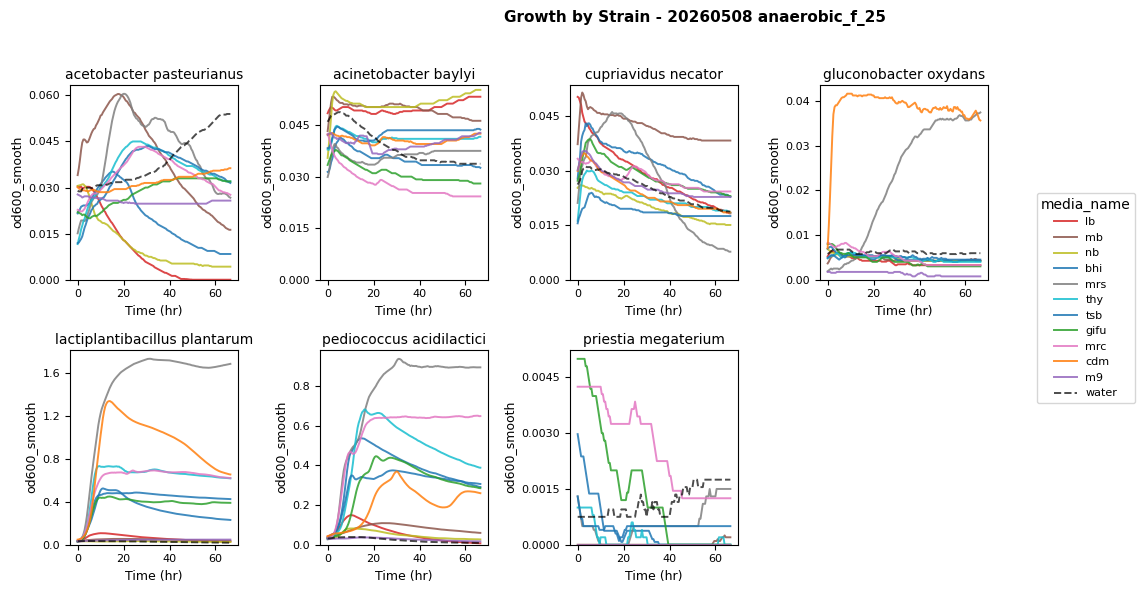

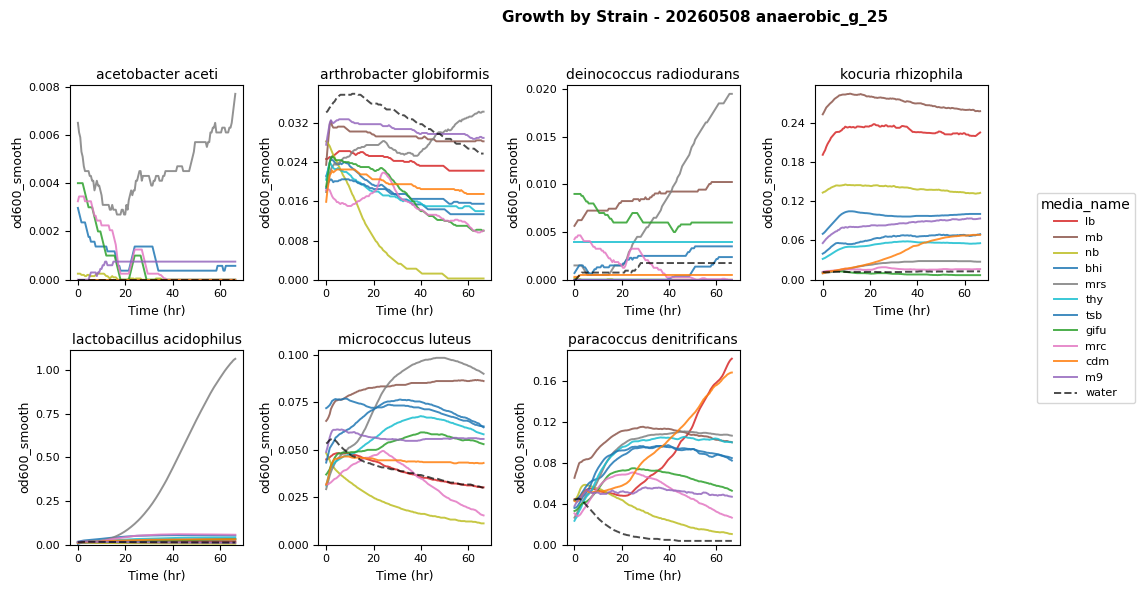

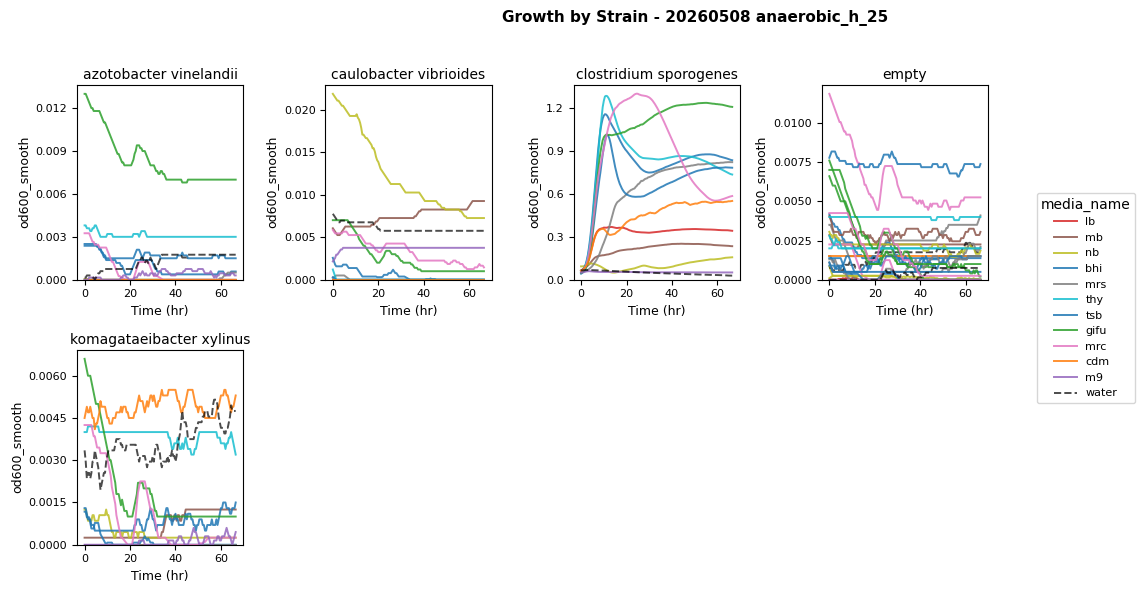

In [29]:
figs = plot_growth_curves_by_strain(df_anaerobic, time_unit="hr", od_col="od600_smooth")

## 2. Growth parameters

### MaxOD600 Heatmap

Prepared Curves DataFrame has 1078 rows
Prepared Curves DataFrame has 1078 rows after growth threshold removal


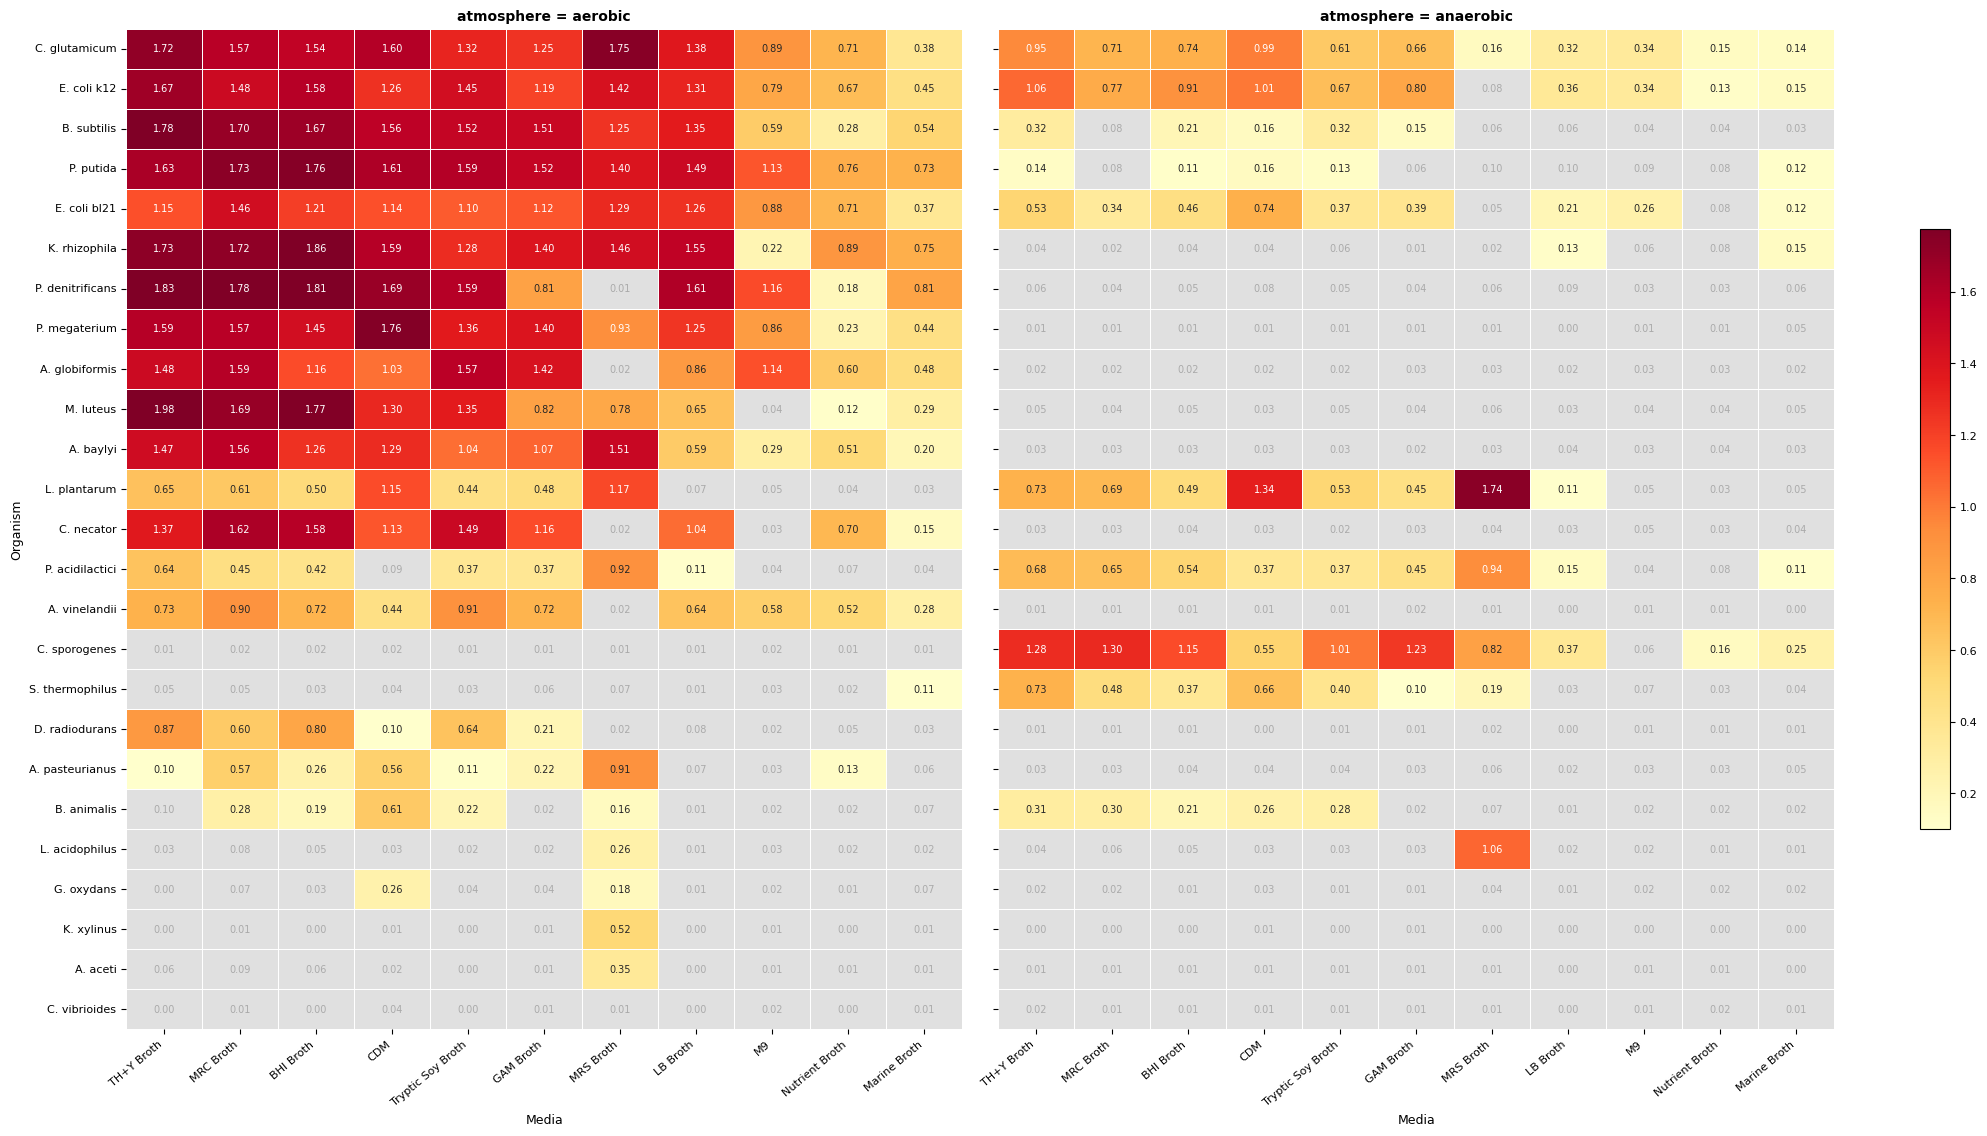

In [30]:
from src.dataset.plots import plot_maxod_heatmap


fig = plot_maxod_heatmap(df_aero_anaero_curves, 
                         align_df=False, 
                         facet_col="atmosphere", 
                         filter_param_outliers=False)

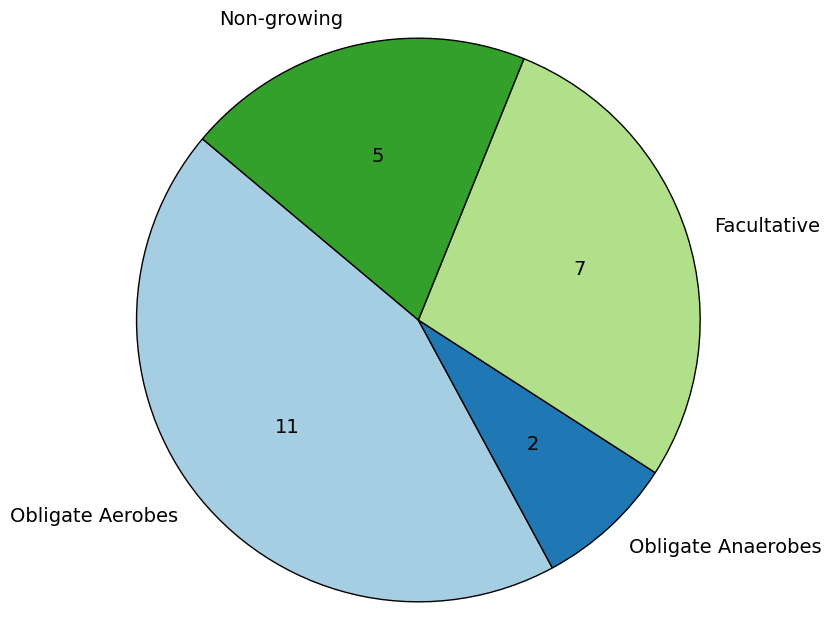

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data based on the organism categorization
categories = [
    'Obligate Aerobes', 
    'Obligate Anaerobes', 
    'Facultative', 
    'Non-growing'
]
counts = [11, 2, 7, 5   ]

# Use seaborn's "Paired" color palette
colors = sns.color_palette("Paired", len(categories))

# Create the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    counts, 
    labels=categories, 
    colors=colors, 
    # Lambda function converts the percentage back to the original count integer
    autopct=lambda p: '{:.0f}'.format(p * sum(counts) / 100), 
    startangle=140,    
    wedgeprops={'edgecolor': 'black'},
    textprops={'fontsize': 14} # Makes all labels and inner numbers bigger
)

# Ensure the pie chart is drawn as a perfect circle
plt.axis('equal')  

# Display the plot
plt.show()

Prepared Curves DataFrame has 1078 rows
Prepared Curves DataFrame has 1078 rows after growth threshold removal
Prepared Curves DataFrame has 1078 rows
Prepared Curves DataFrame has 1078 rows after growth threshold removal


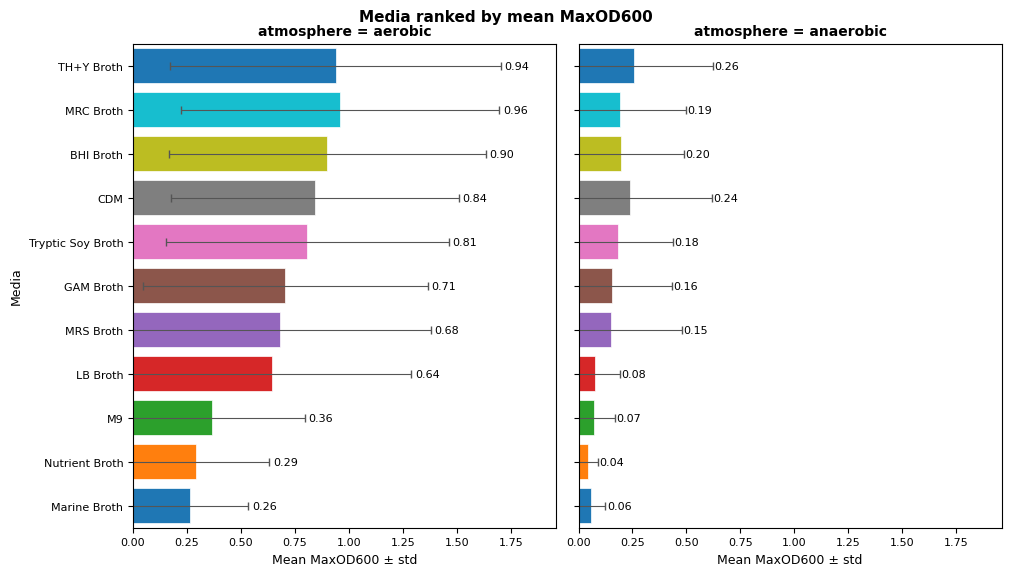

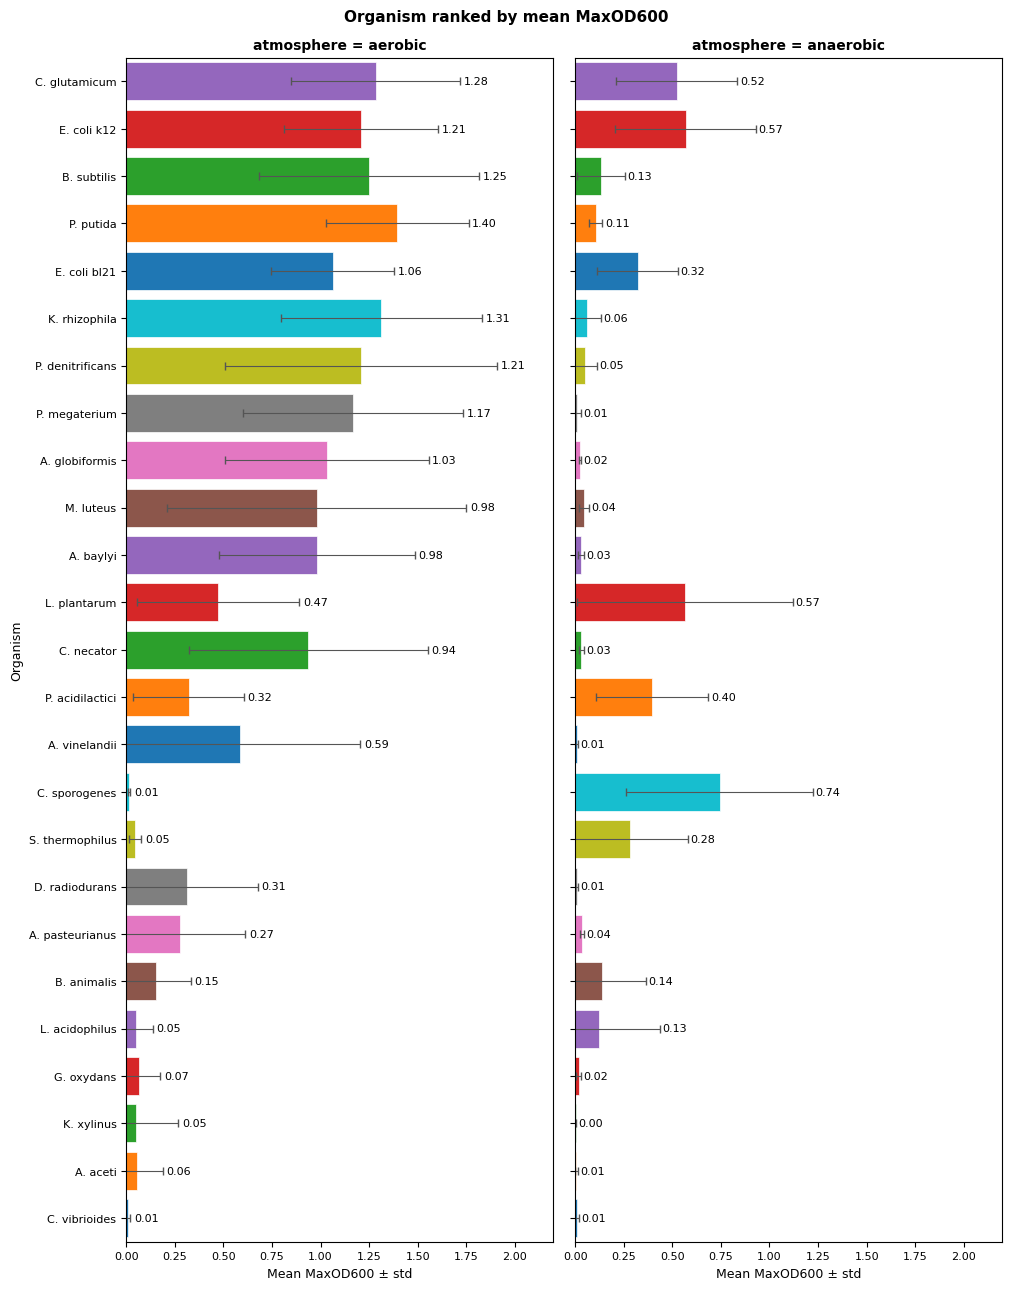

In [36]:
from src.dataset.plots import plot_maxod_ranking

fig = plot_maxod_ranking(df_aero_anaero_curves)
fig = plot_maxod_ranking(df_aero_anaero_curves,
                          group_by="Organism")


### Growth rate

Prepared Curves DataFrame has 1078 rows
Prepared Curves DataFrame has 1078 rows after growth threshold removal
Filtered 135 outliers in 'growth_rate' (IQR fence [-0.8144, 1.731])


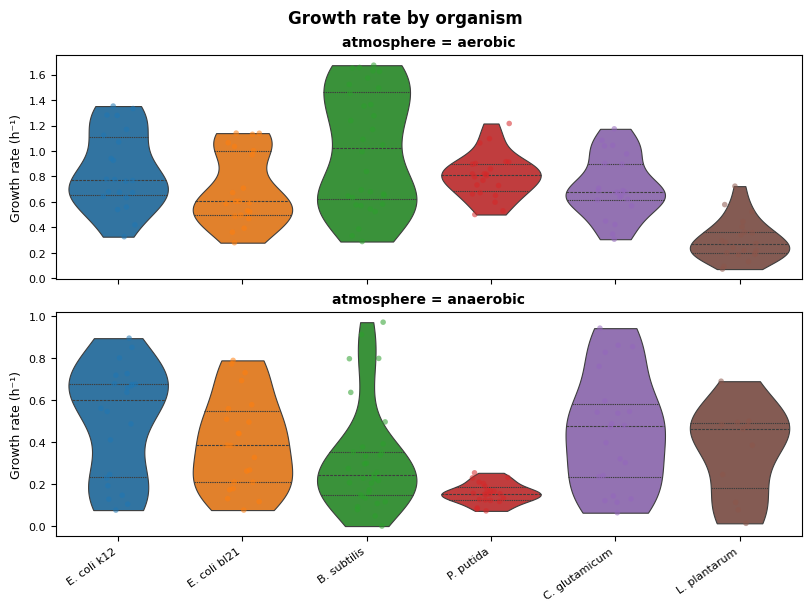

In [33]:
from src.dataset.plots import plot_growth_rate_violin

organisms = [
    "escherichia coli k12",
    "escherichia coli bl21",
    "bacillus subtilis",
    "pseudomonas putida",
    "corynebacterium glutamicum",
    "lactiplantibacillus plantarum",
]
fig = plot_growth_rate_violin(df_aero_anaero_curves, organisms, filter_param_outliers=True)